In [35]:
# Alunos: Ian Luca Marinho Aguiar / João Pedro Menezes Barros Dantas de Souza / Davi da Cunha Ribeiro
# Turma: 1708-OBG

# Manipulação dos dados
import pandas as pd

# Visualizações
import plotly.express as px 

In [36]:
bd_25 = pd.ExcelFile("Sinopse_Estatistica_da_Educação_Basica_2025_V2.xlsx") # Importa o banco de dados de Sinopse de Educação Básica 2025
bd_20 = pd.ExcelFile("Sinopse_Estatistica_da_Educação_Basica_2020.xlsx") # Importa o banco de dados de Sinopse de Educação Básica 2020
bd_15 = pd.ExcelFile("Sinopse_Estatistica_da_Educação_Basica_2015.xlsx") # Importa o banco de dados de Sinopse de Educação Básica 2015

# É importante ressaltar que o banco de dados de 2020 (nomeado como 'bd_20') é de 08/03/2021, atualizado após as instabilidades conferidas
# pela pandemia de COVID-19 que afetou o cenário educacional nacional.

# Tabelas que serão utilizadas para responder às qeustões 1, 2 e 3
tb_11_2025 = pd.read_excel(bd_25, sheet_name = "Educação Básica 1.1")
tb_155_2025 = pd.read_excel(bd_25, sheet_name = "Educação Especial 1.55")
tb_158_2025 = pd.read_excel(bd_25, sheet_name = "1.58") # No ano de 2025, a aba que contém as informações sobre alunos com diagnóstico
# de superdotação e TEA's é nomeada de maneira distinta dos anos anteriores, como "1.58".

tb_11_2020 = pd.read_excel(bd_20, sheet_name = "Educação Básica 1.1")
tb_138_2020 = pd.read_excel(bd_20, sheet_name = "Educação Especial 1.38")
tb_143_2020 = pd.read_excel(bd_20, sheet_name = "1.43")
tb_149_2020 = pd.read_excel(bd_20, sheet_name = "1.49")


tb_11_2015 = pd.read_excel(bd_15, sheet_name = "Educação Básica 1.1")
tb_138_2015 = pd.read_excel(bd_15, sheet_name = "Educação Especial 1.38")
tb_143_2015 = pd.read_excel(bd_15, sheet_name = "1.43")
tb_149_2015 = pd.read_excel(bd_15, sheet_name = "1.49")


,Região,Estado,Município,IBGE,2015,2020,2025
0,Brasil,<NA>,<NA>,<NA>,1.91,2.77,5.34
1,Norte,<NA>,<NA>,<NA>,1.57,2.56,5.13
2,Norte,Rondônia,<NA>,<NA>,2.34,3.18,6.09
3,Norte,Rondônia,Alta Floresta D'Oeste,1100015,2.49,2.14,4.79
4,Norte,Rondônia,Alto Alegre dos Parecis,1100379,2.79,2.58,4.99
...,...,...,...,...,...,...,...
5599,Centro-Oeste,Goiás,Vicentinópolis,5222054,2.65,2.10,4.61
5600,Centro-Oeste,Goiás,Vila Boa,5222203,2.04,1.91,4.07
5601,Centro-Oeste,Goiás,Vila Propício,5222302,2.88,3.40,8.99
5602,Centro-Oeste,Distrito Federal,<NA>,<NA>,2.45,2.64,4.78


,Ano,Percentual
0,Região,Brasil
1,Estado,<NA>
2,Município,<NA>
3,IBGE,<NA>
4,2015,1.91
5,2020,2.77
6,2025,5.34


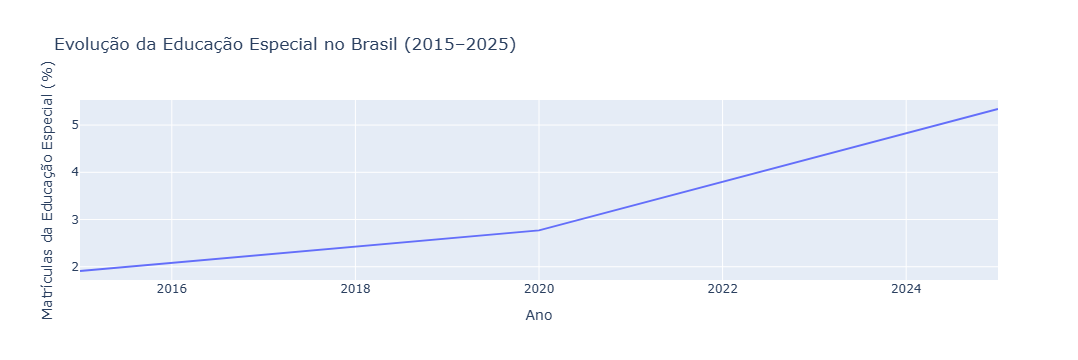

In [34]:
# Pergunta 1:
# Como evoluíram as matrículas da educação especial entre 2015 e 2025, em comparação com o total da educação básica?

# Aqui, a resposta será dada por meio da porcentagem de matrículas de alunos especiais com relação às matrículas totais.
# A visualização será dada por meio uma série temporal com intervalos de 5 anos.

tabelas = {
    2015: (tb_11_2015, tb_138_2015),
    2020: (tb_11_2020, tb_138_2020),
    2025: (tb_11_2025, tb_155_2025)
}

# Função para limpar a tabela e retirar as inconsistências que as células mescladas induzem na análise dos dados
def limpar(df):
    df = df.iloc[:, :5].copy()
    df.columns = ["Região", "Estado", "Município", "IBGE", "Total"]

    df["Total"] = pd.to_numeric(df["Total"], errors="coerce")
    df["IBGE"] = pd.to_numeric(df["IBGE"], errors="coerce").astype("Int64")
    df = df[df["Total"].notna()].copy()
    
    for coluna in ["Região", "Estado", "Município"]:
        df[coluna] = df[coluna].astype("string").str.strip().replace("", pd.NA)
        df[coluna] = df[coluna].replace("<NA>", "-")

    df["id"] = "REG:" + df["Região"]
    df.loc[df["Estado"].notna(), "id"] = "UF:" + df["Estado"]
    df.loc[df["IBGE"].notna(), "id"] = "MUN:" + df["IBGE"].astype("string")

    df = df.dropna(subset=["id"])
    return df.set_index("id")


# Monta a view a partir das localidades de 2025 (escolhemos utilizar os padrões de 2025 e não os de 2015 e 2020)
view = limpar(tb_11_2025)[["Região", "Estado", "Município", "IBGE"]].copy()

# Calcula os percentuais
for ano, (basica, especial) in tabelas.items():
    total = limpar(basica)["Total"]
    esp = limpar(especial)["Total"]

    view[ano] = (esp / total * 100).round(2)

view = view.reset_index(drop=True)

display(view)


#Utilizando o Altair, podemos projetar uma série temporal num plano bidimensional:

view_brasil = view.loc[view["Região"] == "Brasil"].melt(var_name="Ano", value_name = "Percentual")

display(view_brasil)

# Gráfico bidimensional
fig = px.line(view_brasil, x = "Ano", y = "Percentual", title = "Evolução da Educação Especial no Brasil (2015–2025)", 
              labels = {"Ano": "Ano", "Percentual": "Matrículas da Educação Especial (%)"})
fig.show()

In [16]:
# Pergunta 2:
# Como as matrículas se dividem entre deficiências, TEA e altas habilidades, e como essa composição mudou ao longo dos
# anos?





In [ ]:
# Pergunta 3:
# Em que etapas de ensino estão esses alunos, e a presença deles diminui ao longo da trajetória escolar?


